In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# PHASE 1 — IMPROVED WOUND CLASSIFICATION (MobileNetV2)
# Add these cells BEFORE your existing Phase 2 cells in the notebook

In [57]:
 
# ── Cell 1 : Imports & Config ────────────────────────────────
import os, cv2, torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)
 
# ── Kaggle dataset paths (adjust if your dataset slug differs) ──
TRAIN_DIR  = "/kaggle/input/datasets/prjwal07/traindataimages/Train"
TEST_DIR   = "/kaggle/input/datasets/prjwal07/testimagedataset/Test"
TRAIN_CSV  = f"{TRAIN_DIR}/wound_locations_Labels_AZH_Train.csv"
TEST_CSV   = f"{TEST_DIR}/wound_locations_Labels_AZH_Test.csv"
 
BATCH_SIZE = 32
IMG_SIZE   = 224          # ↑ from 128 — better feature extraction
EPOCHS     = 15
LR         = 1e-4
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
 
P1_OUT = "/kaggle/working/phase1_output"
os.makedirs(P1_OUT, exist_ok=True)
 
print(f"Device : {DEVICE}")
print(f"CUDA   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
 

Device : cuda
CUDA   : True
GPU    : Tesla T4


In [58]:
#print(self.df[self.df['filename'].isna()].head())
print(train_dataset.df[train_dataset.df['filename'].isna()].head())

Empty DataFrame
Columns: [index, Locations, Labels, class_folder, img_id, filename]
Index: []


In [60]:
# ── Cell 2 : Dataset ─────────────────────────────────────────
class WoundDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.samples = []
        self.transform = transform

        #self.classes = sorted(os.listdir(img_dir))
        self.classes = sorted([
            d for d in os.listdir(img_dir)
            if os.path.isdir(os.path.join(img_dir, d))
        ])
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}

        for cls in self.classes:
            folder = os.path.join(img_dir, cls)
            for img in os.listdir(folder):
                self.samples.append((os.path.join(folder, img), self.class_to_idx[cls]))

        print(f"Loaded {len(self.samples)} samples | Classes: {self.class_to_idx}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])


print("Building datasets...")
train_dataset = WoundDataset(TRAIN_DIR, train_transform)
test_dataset  = WoundDataset(TEST_DIR, test_transform)


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)

test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)


NUM_CLASSES = len(train_dataset.classes)
CLASS_NAMES = train_dataset.classes

print(f"\nNum classes : {NUM_CLASSES}")
print(f"Class names : {CLASS_NAMES}")


# ✅ Class distribution (new way)
from collections import Counter
labels = [label for _, label in train_dataset.samples]
dist = Counter(labels)

print("\nTrain class distribution:")
for k, v in dist.items():
    print(f"{CLASS_NAMES[k]} : {v}")

Building datasets...
Loaded 696 samples | Classes: {'BG': 0, 'D': 1, 'N': 2, 'P': 3, 'S': 4, 'V': 5}
Loaded 234 samples | Classes: {'BG': 0, 'D': 1, 'N': 2, 'P': 3, 'S': 4, 'V': 5}

Num classes : 6
Class names : ['BG', 'D', 'N', 'P', 'S', 'V']

Train class distribution:
BG : 75
D : 139
N : 75
P : 100
S : 122
V : 185


In [61]:
print(train_dataset.classes)

['BG', 'D', 'N', 'P', 'S', 'V']


In [62]:
img, label = train_dataset[0]
print(img.shape, label)

torch.Size([3, 224, 224]) 0


In [64]:
print(train_dataset.classes)

['BG', 'D', 'N', 'P', 'S', 'V']


In [66]:
import os
print(os.listdir(TRAIN_DIR + "/BG")[:5])

['45.jpg', '56.jpg', '20.jpg', '58.jpg', '6.jpg']


In [68]:
 
# ── Cell 4 : Model — MobileNetV2 with better head ────────────
model = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
 
# Freeze all layers first
for p in model.parameters():
    p.requires_grad = False
 
# Unfreeze last 4 InvertedResidual blocks for domain adaptation
for p in model.features[-4:].parameters():
    p.requires_grad = True
 
# Better classifier head: two-layer MLP with dropout
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(model.last_channel, 512),
    nn.ReLU(inplace=True),
    nn.BatchNorm1d(512),
    nn.Dropout(p=0.3),
    nn.Linear(512, NUM_CLASSES),
)
model = model.to(DEVICE)
 
trainable  = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_p    = sum(p.numel() for p in model.parameters())
print(f"Trainable params : {trainable:,} / {total_p:,}  ({trainable/total_p*100:.1f}%)")
 

Trainable params : 2,186,054 / 2,883,846  (75.8%)


In [69]:
print(df.columns)

Index(['class_folder', 'class_name', 'filename', 'img_path', 'depth_path',
       'severity_score', 'time_step'],
      dtype='object')


In [71]:
# ── Cell 5 : Training Loop ────────────────────────────────────
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), lr=LR, weight_decay=1e-4
)
EPOCHS = 30
# OneCycleLR: ramps up then down — avoids manual tuning, improves convergence
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr     = LR * 10,
    steps_per_epoch = len(train_loader),
    epochs     = EPOCHS,
    pct_start  = 0.3,
)
 
history = {"loss": [], "acc": []}
 
print(f"\nTraining  — {EPOCHS} epochs | Device: {DEVICE}")
print("=" * 65)
 
for epoch in range(EPOCHS):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0
 
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1:2d}/{EPOCHS}", leave=False)
    for imgs, labels in loop:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
 
        optimizer.zero_grad(set_to_none=True)
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
 
        epoch_loss += loss.item()
        preds       = logits.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)
        loop.set_postfix(loss=f"{loss.item():.4f}")
 
    avg_loss = epoch_loss / len(train_loader)
    avg_acc  = correct / total
    history["loss"].append(avg_loss)
    history["acc"].append(avg_acc)
 
    lr_now = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch+1:2d}/{EPOCHS} | Loss: {avg_loss:.4f} | "
          f"Acc: {avg_acc:.4f} | LR: {lr_now:.2e}")
 
print("\nTraining complete.")
 


Training  — 30 epochs | Device: cuda


Epoch  1/30 | Loss: 0.6651 | Acc: 0.9181 | LR: 6.92e-05


Epoch  2/30 | Loss: 0.6326 | Acc: 0.9267 | LR: 1.53e-04


Epoch  3/30 | Loss: 0.6299 | Acc: 0.9353 | LR: 2.82e-04


Epoch  4/30 | Loss: 0.6387 | Acc: 0.9267 | LR: 4.40e-04


Epoch  5/30 | Loss: 0.6315 | Acc: 0.9411 | LR: 6.08e-04


... (21 outputs left out)

Epoch 27/30 | Loss: 0.5274 | Acc: 0.9842 | LR: 4.81e-05


Epoch 28/30 | Loss: 0.5280 | Acc: 0.9856 | LR: 2.12e-05


Epoch 29/30 | Loss: 0.5247 | Acc: 0.9871 | LR: 5.09e-06


Epoch 30/30 | Loss: 0.5136 | Acc: 0.9885 | LR: 1.56e-08

Training complete.


In [72]:

 
# ── Cell 6 : Evaluation on Test Set ──────────────────────────
model.eval()
all_preds, all_labels, all_probs = [], [], []
 
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating"):
        imgs   = imgs.to(DEVICE)
        logits = model(imgs)
        probs  = torch.softmax(logits, dim=1)
        preds  = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())
 
all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)
 
acc  = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
rec  = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
f1   = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
 
print("\n" + "=" * 55)
print("PHASE 1 — TEST RESULTS")
print("=" * 55)
print(f"  Accuracy  : {acc:.4f}  ({acc:.2%})")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))
 

Evaluating: 100%|██████████| 8/8 [00:01<00:00,  4.38it/s]


PHASE 1 — TEST RESULTS
  Accuracy  : 0.8205  (82.05%)
  Precision : 0.8255
  Recall    : 0.8205
  F1-Score  : 0.8206

              precision    recall  f1-score   support

          BG       1.00      0.96      0.98        25
           D       0.86      0.78      0.82        46
           N       0.89      1.00      0.94        25
           P       0.64      0.68      0.66        34
           S       0.76      0.88      0.81        42
           V       0.85      0.76      0.80        62

    accuracy                           0.82       234
   macro avg       0.83      0.84      0.84       234
weighted avg       0.83      0.82      0.82       234



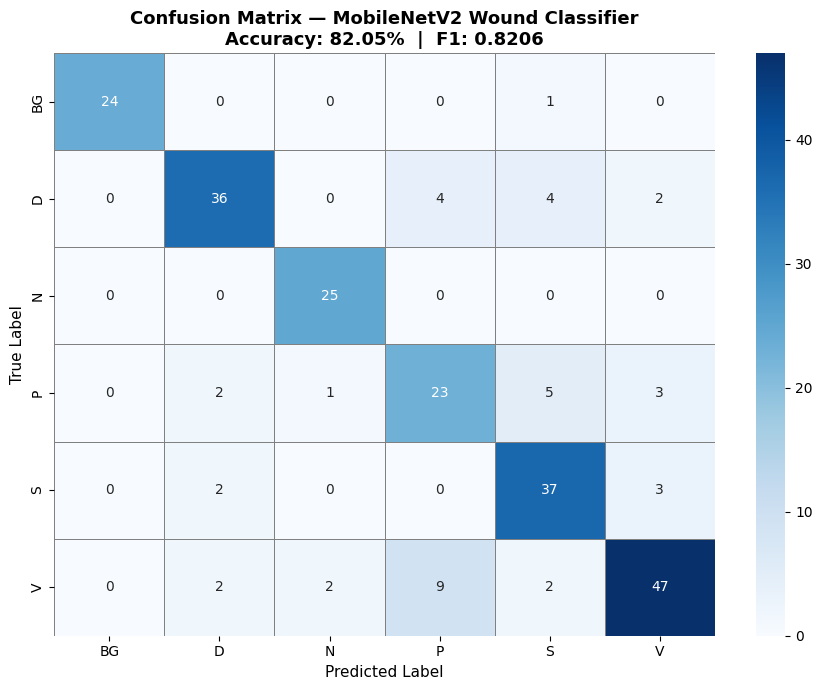

Confusion matrix saved.


In [73]:
 
# ── Cell 7 : Confusion Matrix ─────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)
 
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='gray')
plt.title(f"Confusion Matrix — MobileNetV2 Wound Classifier\n"
          f"Accuracy: {acc:.2%}  |  F1: {f1:.4f}", fontsize=13, fontweight='bold')
plt.ylabel("True Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.tight_layout()
plt.savefig(f"{P1_OUT}/confusion_matrix.png", dpi=150)
plt.show()
print("Confusion matrix saved.")
 

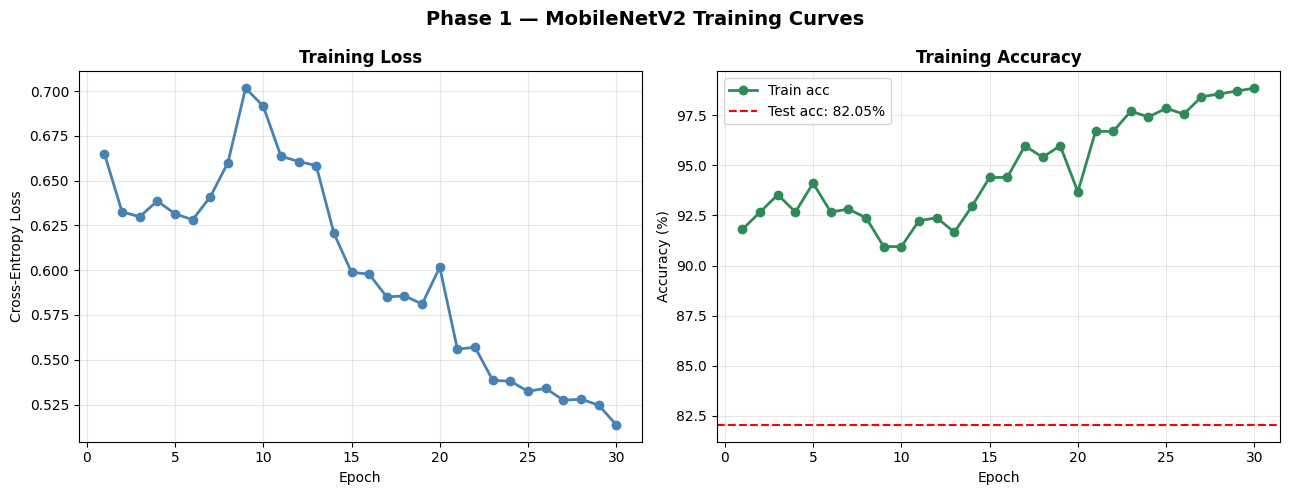

In [74]:
# ── Cell 8 : Training Curves ──────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
 
ax1.plot(range(1, EPOCHS+1), history["loss"], marker='o', color='steelblue', linewidth=2)
ax1.set_title("Training Loss", fontsize=12, fontweight='bold')
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, alpha=0.3)
 
ax2.plot(range(1, EPOCHS+1), [a*100 for a in history["acc"]], marker='o',
         color='seagreen', linewidth=2, label="Train acc")
ax2.axhline(y=acc*100, color='red', linestyle='--', linewidth=1.5,
            label=f"Test acc: {acc:.2%}")
ax2.set_title("Training Accuracy", fontsize=12, fontweight='bold')
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
ax2.legend(fontsize=10); ax2.grid(True, alpha=0.3)
 
fig.suptitle("Phase 1 — MobileNetV2 Training Curves", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{P1_OUT}/training_curves.png", dpi=150)
plt.show()
 

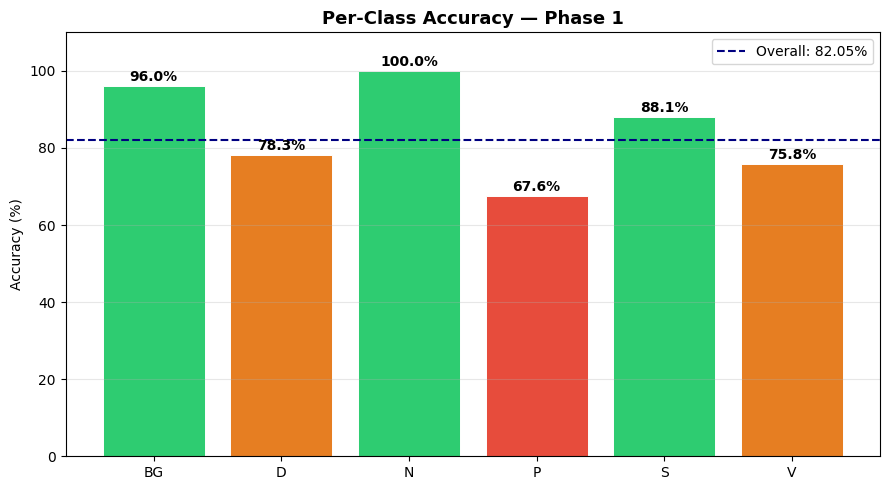

In [75]:

# ── Cell 9 : Per-Class Accuracy Bar Chart ────────────────────
per_class_acc = []
for i, cls in enumerate(CLASS_NAMES):
    mask = all_labels == i
    if mask.sum() > 0:
        per_class_acc.append(all_preds[mask] == i)
    else:
        per_class_acc.append(np.array([]))
 
class_accs = [arr.mean() * 100 if len(arr) > 0 else 0 for arr in per_class_acc]
colors_bar  = ['#2ecc71' if a >= 85 else '#e67e22' if a >= 70 else '#e74c3c'
               for a in class_accs]
 
plt.figure(figsize=(9, 5))
bars = plt.bar(CLASS_NAMES, class_accs, color=colors_bar, edgecolor='white', linewidth=0.7)
plt.axhline(y=acc*100, color='navy', linestyle='--', linewidth=1.5,
            label=f"Overall: {acc:.2%}")
for bar, val in zip(bars, class_accs):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{val:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.title("Per-Class Accuracy — Phase 1", fontsize=13, fontweight='bold')
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f"{P1_OUT}/per_class_accuracy.png", dpi=150)
plt.show()

In [76]:

 
# ── Cell 10 : Save Model Checkpoint ──────────────────────────
CKPT_PATH = "/kaggle/working/mobilenetv2_wound_classifier.pth"
torch.save({
    'model_state_dict' : model.state_dict(),
    'class_to_idx'     : train_dataset.class_to_idx,
    'classes'          : CLASS_NAMES,
    'accuracy'         : acc,
    'f1'               : f1,
    'num_classes'      : NUM_CLASSES,
    'img_size'         : IMG_SIZE,
}, CKPT_PATH)
 
print(f"Model saved → {CKPT_PATH}")
print(f"\n{'='*55}")
print(f"Phase 1 done. Accuracy: {acc:.2%}  |  F1: {f1:.4f}")
print(f"{'='*55}")
print(f"\nOutputs saved to {P1_OUT}/")
 

Model saved → /kaggle/working/mobilenetv2_wound_classifier.pth

Phase 1 done. Accuracy: 82.05%  |  F1: 0.8206

Outputs saved to /kaggle/working/phase1_output/


In [ ]:
!pip install timm --quiet

Imports 

In [77]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image
from pathlib import Path
from tqdm import tqdm

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


Config (all paths in one place)

In [78]:
BASE_PATH = "/kaggle/input/datasets/prjwal07/traindataimages/Train"

# Only wound classes, skip BG and N
CLASSES = {
    "D": "Diabetic (DFU)",
    "P": "Pressure (PU)",
    "S": "Surgical (SW)",
    "V": "Venous (VLU)"
}

OUTPUT_DIR = "/kaggle/working/stage2_output"
DEPTH_DIR  = f"{OUTPUT_DIR}/depth_maps"
PLOT_DIR   = f"{OUTPUT_DIR}/plots"

for d in [OUTPUT_DIR, DEPTH_DIR, PLOT_DIR]:
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
print("\nImage counts per class:")
for cls in CLASSES:
    path = f"{BASE_PATH}/{cls}"
    imgs = [f for f in os.listdir(path) if f.endswith('.jpg')]
    print(f"  {cls} ({CLASSES[cls]}): {len(imgs)} images")

Using device: cuda

Image counts per class:
  D (Diabetic (DFU)): 139 images
  P (Pressure (PU)): 100 images
  S (Surgical (SW)): 122 images
  V (Venous (VLU)): 185 images


Midas Model

In [79]:
# Loading MiDaS small — fast enough for T4, good enough for depth estimation
midas = torch.hub.load("intel-isl/MiDaS", "MiDaS_small", trust_repo=True)
midas.to(DEVICE)
midas.eval()

# Load the transforms that MiDaS expects
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms", trust_repo=True)
transform = midas_transforms.small_transform

print("MiDaS model loaded successfully")

Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/rwightman_gen-efficientnet-pytorch_master


Loading weights:  None
MiDaS model loaded successfully


Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


Function to get depth map for one image

In [80]:
def get_depth_map(img_path):
    """
    Takes an image path, returns:
      - depth_map: 2D numpy array (H x W), raw MiDaS output
      - depth_norm: same map normalized to 0-255 (for visualization)
    """
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    input_batch = transform(img_rgb).to(DEVICE)
    
    with torch.no_grad():
        depth = midas(input_batch)
        depth = torch.nn.functional.interpolate(
            depth.unsqueeze(1),
            size=img_rgb.shape[:2],
            mode="bicubic",
            align_corners=False
        ).squeeze()
    
    depth_map = depth.cpu().numpy()
    
    # Normalize to 0-255 for visualization
    depth_norm = cv2.normalize(depth_map, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)
    
    return depth_map, depth_norm


def compute_severity_score(depth_map):
    """
    Severity score = mean depth of the central wound region.
    We take the central 50% of the image as a proxy for the wound ROI
    (since AZH images are already cropped to the wound).
    Score is higher for deeper/more severe wounds.
    """
    h, w = depth_map.shape
    # Central crop: middle 50% of height and width
    y1, y2 = h // 4, 3 * h // 4
    x1, x2 = w // 4, 3 * w // 4
    wound_region = depth_map[y1:y2, x1:x2]
    
    mean_depth = np.mean(wound_region)
    wound_area  = np.sum(wound_region > np.mean(depth_map))  # pixels deeper than average
    
    score = mean_depth * (wound_area / wound_region.size)
    return float(score)

print("Functions defined.")

Functions defined.


 Run MiDaS on all images, compute scores (this takes ~5-8 mins)

In [81]:
results = []  # will hold one dict per image

for cls_folder, cls_name in CLASSES.items():
    img_dir = f"{BASE_PATH}/{cls_folder}"
    images  = sorted([f for f in os.listdir(img_dir) if f.endswith('.jpg')])
    
    print(f"\nProcessing {cls_name} — {len(images)} images...")
    
    # Save depth maps for this class
    cls_depth_dir = f"{DEPTH_DIR}/{cls_folder}"
    os.makedirs(cls_depth_dir, exist_ok=True)
    
    for img_file in tqdm(images, desc=cls_name):
        img_path = f"{img_dir}/{img_file}"
        
        depth_map, depth_norm = get_depth_map(img_path)
        score = compute_severity_score(depth_map)
        
        # Save normalized depth map as image
        depth_save_path = f"{cls_depth_dir}/{img_file}"
        cv2.imwrite(depth_save_path, depth_norm)
        
        results.append({
            "class_folder": cls_folder,
            "class_name":   cls_name,
            "filename":     img_file,
            "img_path":     img_path,
            "depth_path":   depth_save_path,
            "severity_score": score
        })

df = pd.DataFrame(results)
df.to_csv(f"{OUTPUT_DIR}/severity_scores.csv", index=False)
print(f"\nDone. Total images processed: {len(df)}")
print(df.groupby("class_folder")["severity_score"].describe().round(2))


Processing Diabetic (DFU) — 139 images...


Diabetic (DFU): 100%|██████████| 139/139 [00:02<00:00, 51.23it/s]



Processing Pressure (PU) — 100 images...


Pressure (PU): 100%|██████████| 100/100 [00:01<00:00, 51.16it/s]



Processing Surgical (SW) — 122 images...


Surgical (SW): 100%|██████████| 122/122 [00:03<00:00, 33.39it/s]



Processing Venous (VLU) — 185 images...


Venous (VLU): 100%|██████████| 185/185 [00:03<00:00, 50.48it/s]


Done. Total images processed: 546
              count    mean     std    min     25%     50%     75%      max
class_folder                                                               
D             139.0  646.79  239.65  58.49  516.17  680.52  820.13  1225.34
P             100.0  489.38  257.67   0.00  274.80  527.64  711.36   948.64
S             122.0  428.73  247.72  12.55  211.54  413.06  638.72   974.56
V             185.0  461.87  235.27   0.10  293.77  491.69  615.46  1086.92


Build synthetic time-series sequences

In [82]:
# Sort each class by severity descending → rank = time step
df["time_step"] = df.groupby("class_folder")["severity_score"] \
                    .rank(ascending=False, method="first").astype(int)

df_sorted = df.sort_values(["class_folder", "time_step"]).reset_index(drop=True)

# Normalize time steps to 0-1 range for fair comparison across classes
df_sorted["time_norm"] = df_sorted.groupby("class_folder")["time_step"] \
                                   .transform(lambda x: (x - x.min()) / (x.max() - x.min()))

df_sorted.to_csv(f"{OUTPUT_DIR}/sequences.csv", index=False)

print("Synthetic sequences built.")
print("\nFirst 5 entries of DFU sequence (T0=most severe → healed):")
print(df_sorted[df_sorted["class_folder"]=="D"][
    ["filename","severity_score","time_step"]
].head(5).to_string(index=False))

Synthetic sequences built.

First 5 entries of DFU sequence (T0=most severe → healed):
 filename  severity_score  time_step
 95_0.jpg     1225.337646          1
134_1.jpg     1165.791911          2
 31_0.jpg     1023.651978          3
 20_0.jpg      999.357555          4
 79_0.jpg      997.350547          5


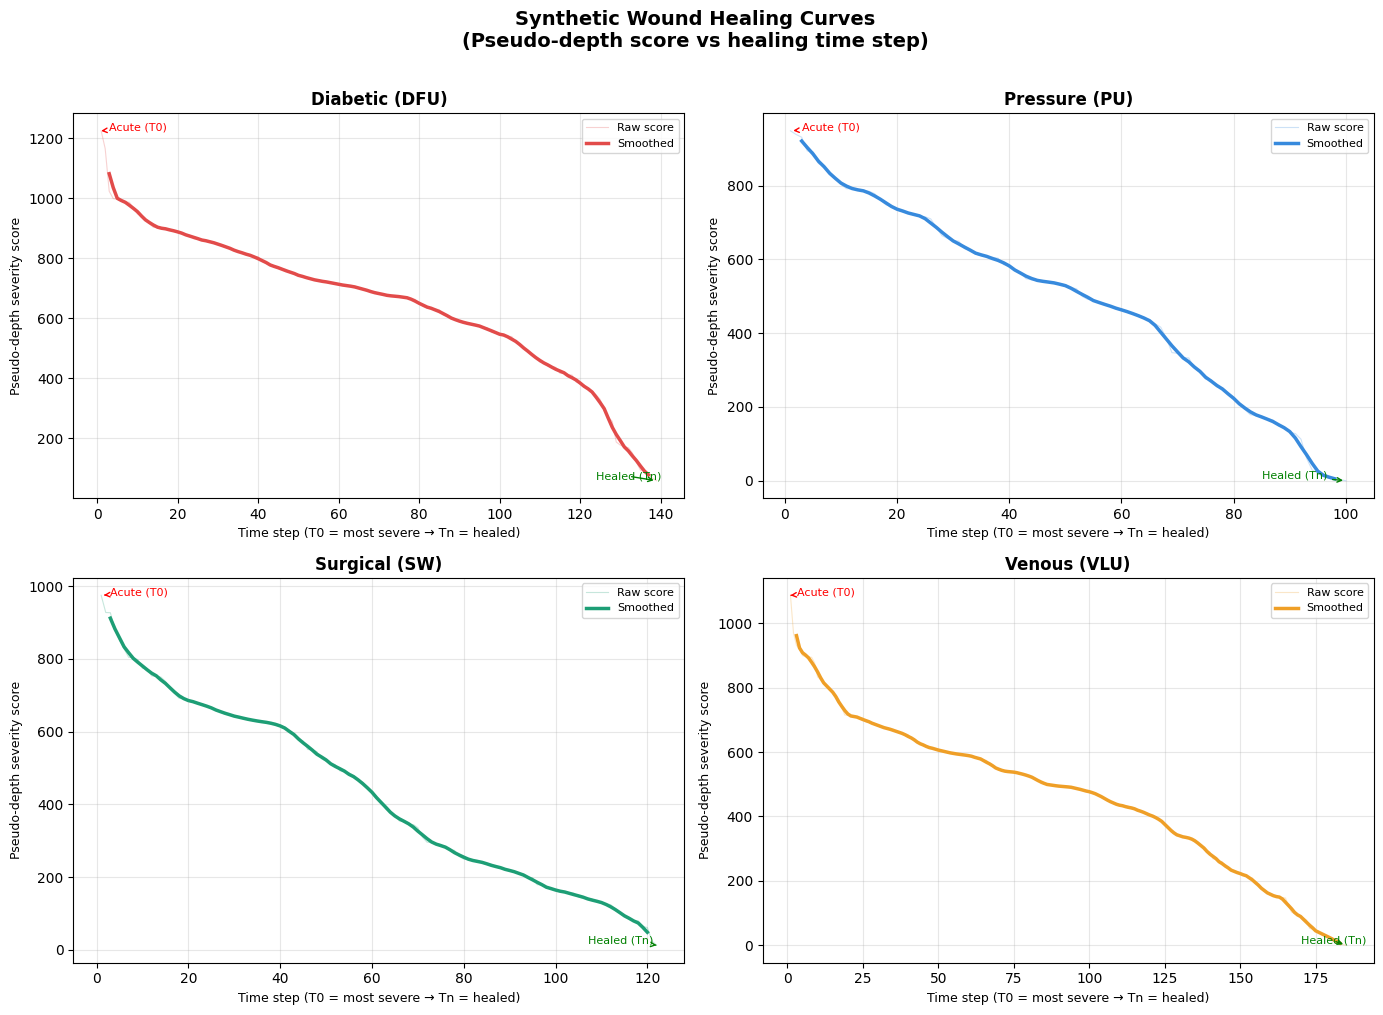

Healing curves saved.


In [83]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Synthetic Wound Healing Curves\n(Pseudo-depth score vs healing time step)",
             fontsize=14, fontweight='bold', y=1.01)

colors = {"D": "#E24B4A", "P": "#378ADD", "S": "#1D9E75", "V": "#EF9F27"}

for ax, (cls_folder, cls_name) in zip(axes.flat, CLASSES.items()):
    cls_df = df_sorted[df_sorted["class_folder"] == cls_folder].copy()
    
    # Smooth with rolling average for cleaner curve
    cls_df["score_smooth"] = cls_df["severity_score"].rolling(window=5, center=True).mean()
    
    ax.plot(cls_df["time_step"], cls_df["severity_score"],
            alpha=0.25, color=colors[cls_folder], linewidth=0.8, label="Raw score")
    ax.plot(cls_df["time_step"], cls_df["score_smooth"],
            color=colors[cls_folder], linewidth=2.5, label="Smoothed")
    
    ax.set_title(f"{cls_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Time step (T0 = most severe → Tn = healed)", fontsize=9)
    ax.set_ylabel("Pseudo-depth severity score", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # Annotate start and end
    first = cls_df.iloc[0]
    last  = cls_df.iloc[-1]
    ax.annotate("Acute (T0)", xy=(first["time_step"], first["severity_score"]),
                fontsize=8, color='red',
                xytext=(first["time_step"] + 2, first["severity_score"]),
                arrowprops=dict(arrowstyle='->', color='red', lw=1))
    ax.annotate("Healed (Tn)", xy=(last["time_step"], last["severity_score"]),
                fontsize=8, color='green',
                xytext=(last["time_step"] - 15, last["severity_score"] + 5),
                arrowprops=dict(arrowstyle='->', color='green', lw=1))

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/healing_curves_all_classes.png", dpi=150, bbox_inches='tight')
plt.show()
print("Healing curves saved.")

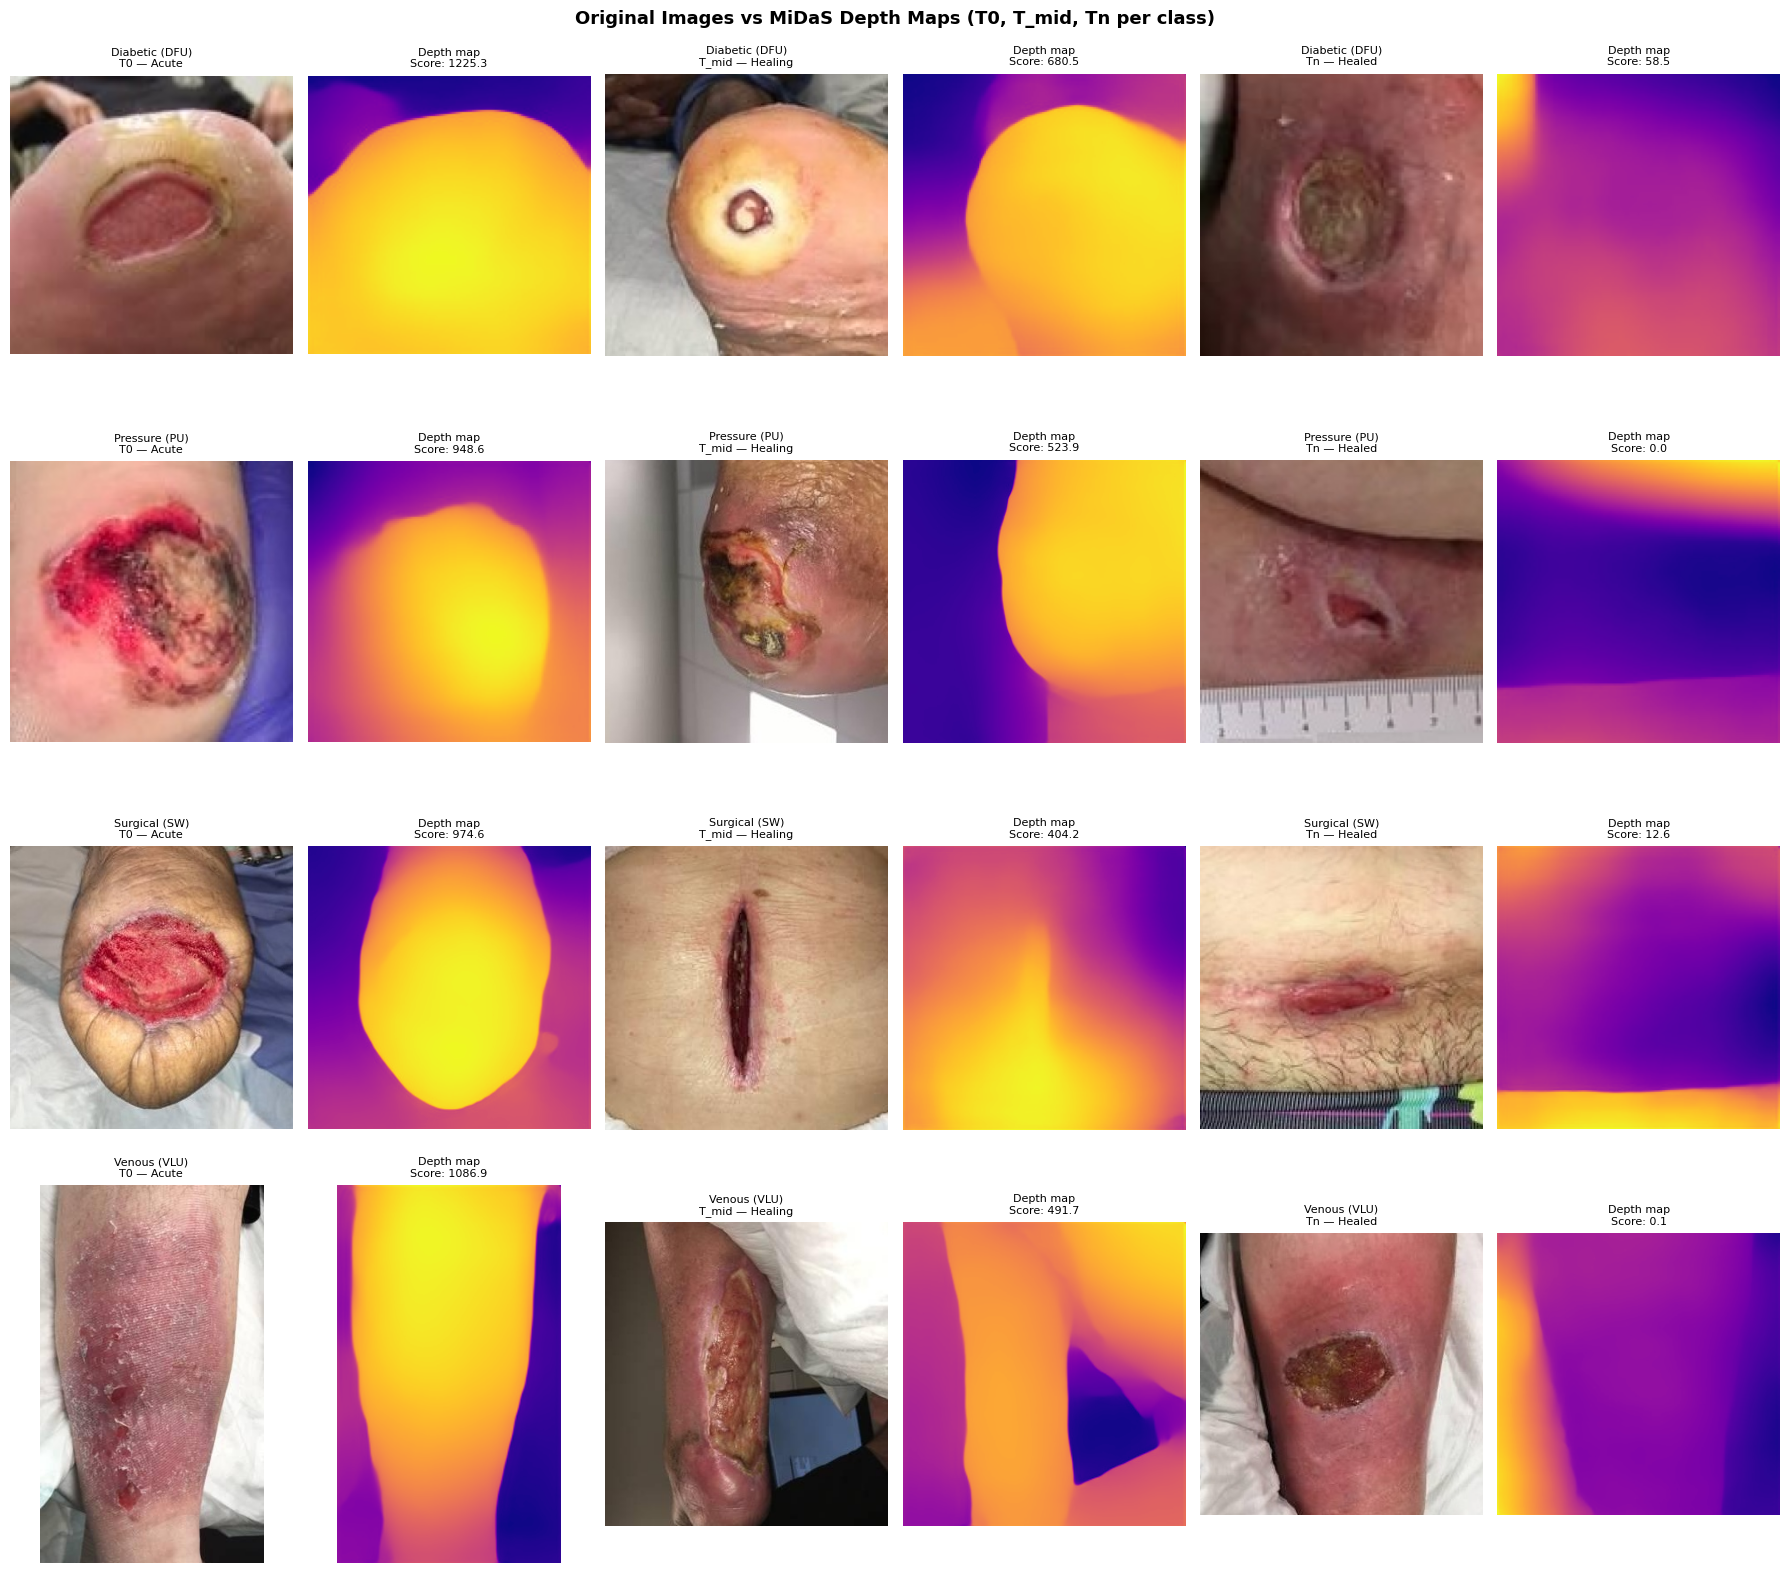

Depth map visualization saved.


In [84]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(18, 4 * len(CLASSES)))
fig.suptitle("Original Images vs MiDaS Depth Maps (T0, T_mid, Tn per class)",
             fontsize=13, fontweight='bold')

for row_idx, (cls_folder, cls_name) in enumerate(CLASSES.items()):
    cls_df = df_sorted[df_sorted["class_folder"] == cls_folder].reset_index(drop=True)
    n = len(cls_df)
    
    # Pick T0 (most severe), middle, Tn (most healed)
    sample_indices = [0, n // 2, n - 1]
    labels = ["T0 — Acute", "T_mid — Healing", "Tn — Healed"]
    
    for col_offset, (idx, label) in enumerate(zip(sample_indices, labels)):
        row = cls_df.iloc[idx]
        
        orig = cv2.cvtColor(cv2.imread(row["img_path"]), cv2.COLOR_BGR2RGB)
        depth_vis = cv2.imread(row["depth_path"], cv2.IMREAD_GRAYSCALE)
        
        # Original
        ax_orig = axes[row_idx][col_offset * 2]
        ax_orig.imshow(orig)
        ax_orig.set_title(f"{cls_name}\n{label}", fontsize=8)
        ax_orig.axis('off')
        
        # Depth map
        ax_dep = axes[row_idx][col_offset * 2 + 1]
        ax_dep.imshow(depth_vis, cmap='plasma')
        ax_dep.set_title(f"Depth map\nScore: {row['severity_score']:.1f}", fontsize=8)
        ax_dep.axis('off')

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/depth_map_visualization.png", dpi=150, bbox_inches='tight')
plt.show()
print("Depth map visualization saved.")

In [85]:
print("=" * 55)
print("STAGE 2 COMPLETE — OUTPUT SUMMARY")
print("=" * 55)

summary = df_sorted.groupby("class_name").agg(
    total_images    = ("filename", "count"),
    max_score       = ("severity_score", "max"),
    min_score       = ("severity_score", "min"),
    score_drop_pct  = ("severity_score", lambda x: round((1 - x.min()/x.max()) * 100, 1))
).reset_index()

summary.columns = ["Class", "Images", "Max Score (T0)", "Min Score (Tn)", "Score Drop (%)"]
print(summary.to_string(index=False))

print(f"\nFiles saved to: {OUTPUT_DIR}")
print(f"  - severity_scores.csv   → raw scores for every image")
print(f"  - sequences.csv         → time-ordered sequences per class")
print(f"  - plots/healing_curves_all_classes.png")
print(f"  - plots/depth_map_visualization.png")
print(f"  - depth_maps/<class>/   → depth map image for every input image")

print("\nThese outputs feed directly into the final pipeline:")
print("  Phase 1 → classifies wound type (DFU / PU / SW / VLU)")
print("  Phase 2 → assigns time step + healing score to that wound")
print("  Combined → 'This is a DFU wound at healing stage T3 of 47'")

STAGE 2 COMPLETE — OUTPUT SUMMARY
         Class  Images  Max Score (T0)  Min Score (Tn)  Score Drop (%)
Diabetic (DFU)     139     1225.337646       58.493127            95.2
 Pressure (PU)     100      948.638562        0.000000           100.0
 Surgical (SW)     122      974.558943       12.553902            98.7
  Venous (VLU)     185     1086.920685        0.098699           100.0

Files saved to: /kaggle/working/stage2_output
  - severity_scores.csv   → raw scores for every image
  - sequences.csv         → time-ordered sequences per class
  - plots/healing_curves_all_classes.png
  - plots/depth_map_visualization.png
  - depth_maps/<class>/   → depth map image for every input image

These outputs feed directly into the final pipeline:
  Phase 1 → classifies wound type (DFU / PU / SW / VLU)
  Phase 2 → assigns time step + healing score to that wound
  Combined → 'This is a DFU wound at healing stage T3 of 47'


In [86]:
import shutil

shutil.make_archive("/kaggle/working/stage2_results", "zip", "/kaggle/working/stage2_output")
print("Done — download stage2_results.zip from the Output panel on the right")

Done — download stage2_results.zip from the Output panel on the right


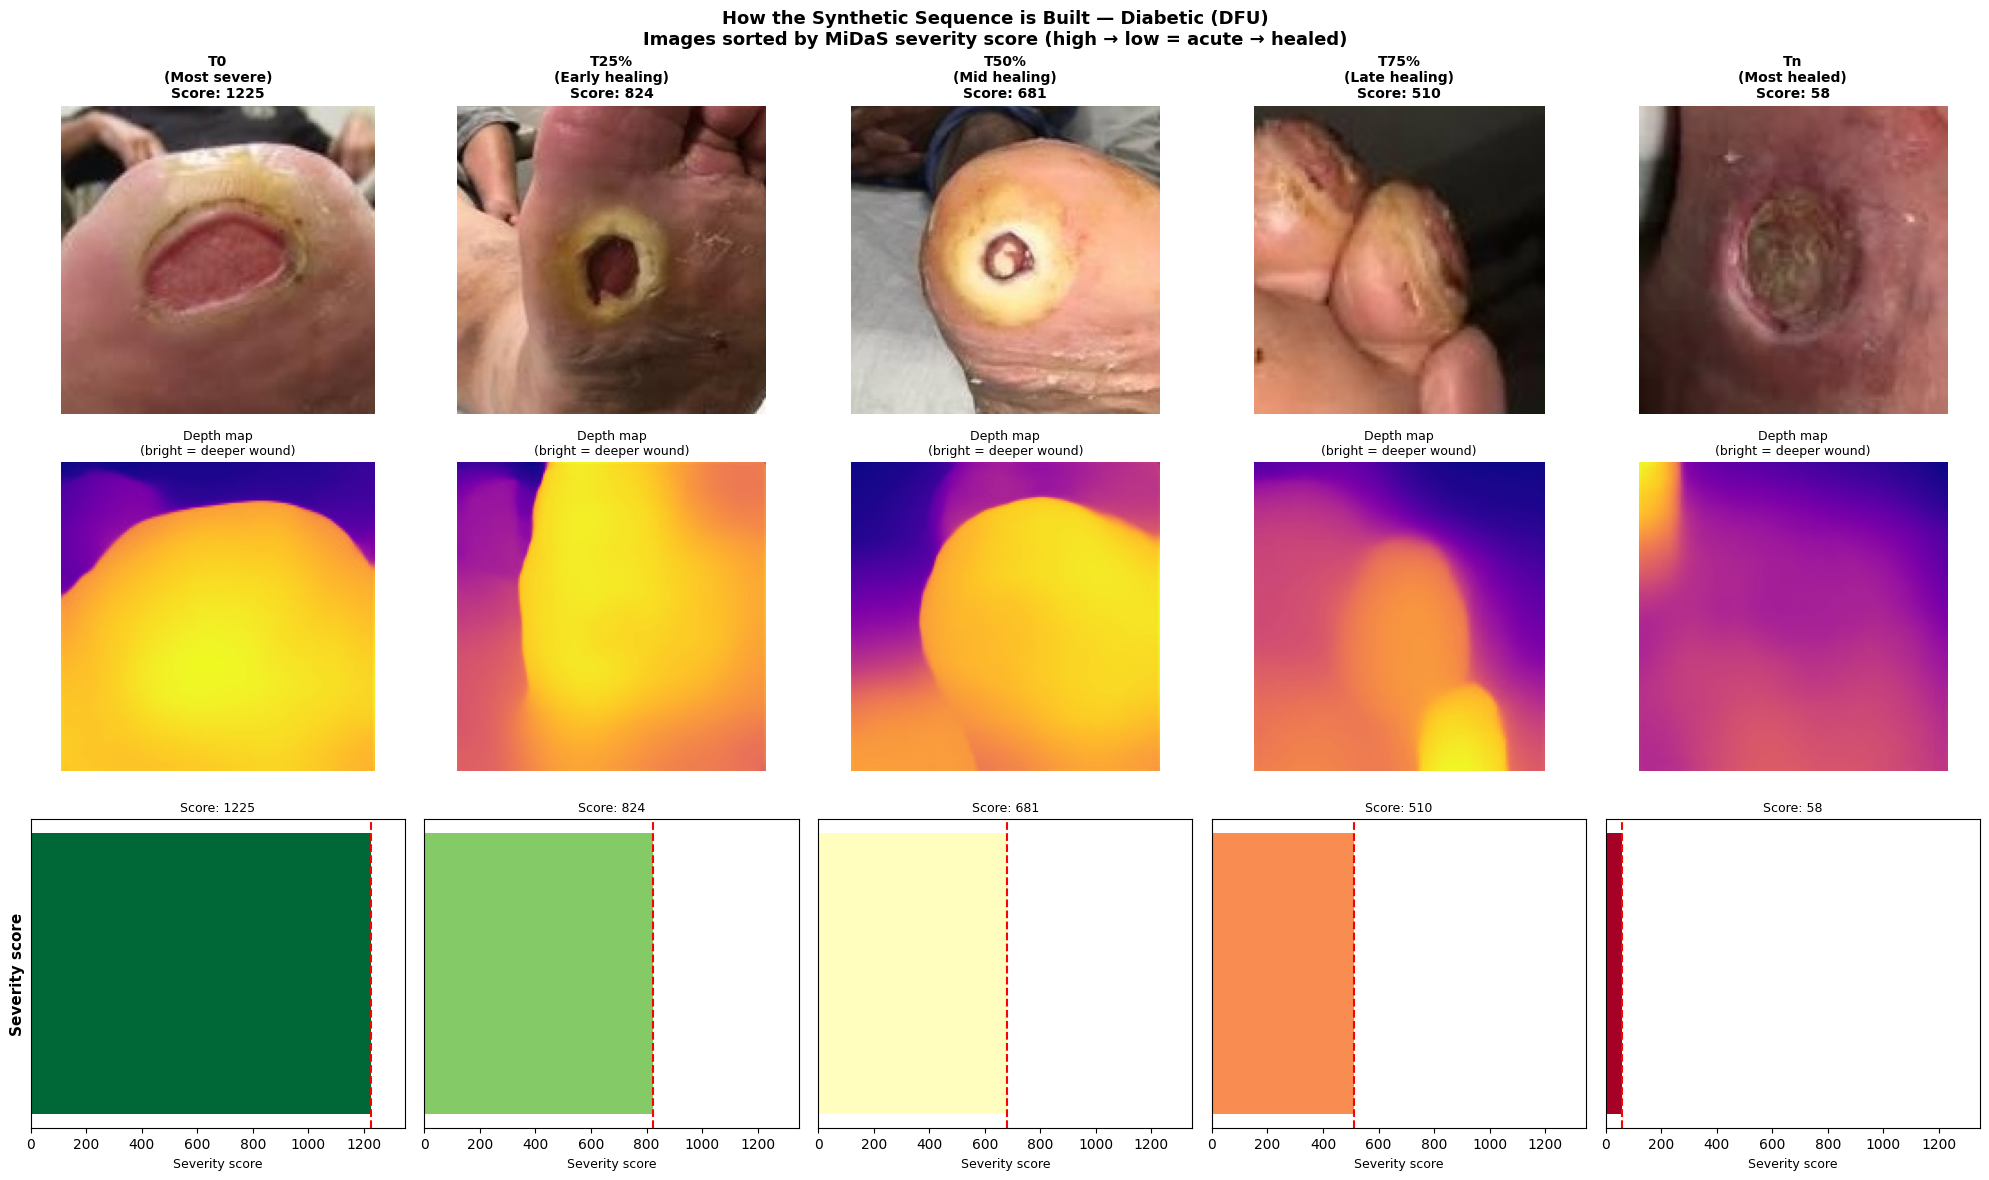


Full DFU sequence has 139 steps
Reading the columns left to right = watching a wound heal over time

Score journey: 1225 → 824 → 681 → 510 → 58


In [87]:
# Pick DFU class and show T0, T25, T50, T75, Tn with original + depth side by side
cls = "D"
cls_name = "Diabetic (DFU)"
cls_df = df_sorted[df_sorted["class_folder"] == cls].reset_index(drop=True)
n = len(cls_df)

# Pick 5 evenly spaced time steps to show the full journey
indices = [0, n//4, n//2, 3*n//4, n-1]
stage_labels = ["T0\n(Most severe)", "T25%\n(Early healing)", 
                "T50%\n(Mid healing)", "T75%\n(Late healing)", 
                "Tn\n(Most healed)"]

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
fig.suptitle(f"How the Synthetic Sequence is Built — {cls_name}\n"
             f"Images sorted by MiDaS severity score (high → low = acute → healed)",
             fontsize=13, fontweight='bold')

for col, (idx, stage_label) in enumerate(zip(indices, stage_labels)):
    row = cls_df.iloc[idx]
    
    orig      = cv2.cvtColor(cv2.imread(row["img_path"]), cv2.COLOR_BGR2RGB)
    depth_vis = cv2.imread(row["depth_path"], cv2.IMREAD_GRAYSCALE)
    
    # Row 0 — original image
    axes[0][col].imshow(orig)
    axes[0][col].set_title(f"{stage_label}\nScore: {row['severity_score']:.0f}", 
                            fontsize=10, fontweight='bold')
    axes[0][col].axis('off')
    axes[0][col].set_xlabel(f"Time step: {row['time_step']}", fontsize=9)
    
    # Row 1 — depth map (plasma colormap: bright = deep)
    im = axes[1][col].imshow(depth_vis, cmap='plasma')
    axes[1][col].set_title("Depth map\n(bright = deeper wound)", fontsize=9)
    axes[1][col].axis('off')
    
    # Row 2 — bar showing score magnitude visually
    axes[2][col].barh([0], [row['severity_score']], 
                       color=plt.cm.RdYlGn_r(row['time_norm']), height=0.4)
    axes[2][col].set_xlim(0, cls_df['severity_score'].max() * 1.1)
    axes[2][col].set_yticks([])
    axes[2][col].set_xlabel("Severity score", fontsize=9)
    axes[2][col].set_title(f"Score: {row['severity_score']:.0f}", fontsize=9)
    axes[2][col].axvline(x=row['severity_score'], color='red', linewidth=1.5, linestyle='--')

# Add row labels on the left
axes[0][0].set_ylabel("Original image", fontsize=11, fontweight='bold')
axes[1][0].set_ylabel("MiDaS depth map", fontsize=11, fontweight='bold')
axes[2][0].set_ylabel("Severity score", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/sequence_internals_DFU.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"\nFull DFU sequence has {n} steps")
print(f"Reading the columns left to right = watching a wound heal over time")
print(f"\nScore journey: {cls_df.iloc[0]['severity_score']:.0f} → "
      f"{cls_df.iloc[n//4]['severity_score']:.0f} → "
      f"{cls_df.iloc[n//2]['severity_score']:.0f} → "
      f"{cls_df.iloc[3*n//4]['severity_score']:.0f} → "
      f"{cls_df.iloc[-1]['severity_score']:.0f}")

In [89]:
import matplotlib.gridspec as gridspec
 
# ── Cell 11 : Wound class constants ──────────────────────────
WOUND_CLASSES = {"D", "P", "S", "V"}    # Only these have depth sequences
 
WOUND_DISPLAY = {
    "D" : "Diabetic Foot Ulcer (DFU)",
    "P" : "Pressure Ulcer (PU)",
    "S" : "Surgical Wound (SW)",
    "V" : "Venous Leg Ulcer (VLU)",
    "BG": "Background (Non-wound)",
    "N" : "Normal Skin (Non-wound)",
}
 
WOUND_COLORS = {
    "D": "#E24B4A",
    "P": "#378ADD",
    "S": "#1D9E75",
    "V": "#EF9F27",
}
 
COMBINED_OUT = "/kaggle/working/combined_output"
os.makedirs(COMBINED_OUT, exist_ok=True)
print("Integration constants ready.")
 
 

Integration constants ready.


In [90]:

 
# ── Cell 12 : Core inference functions ───────────────────────
 
def classify_wound(img_path: str):
    """
    Phase 1 — Run MobileNetV2 on a single image.
    Returns:
        pred_class  : str  e.g. "D"
        confidence  : float  0–1
        all_probs   : dict  {class_name: probability}
    """
    model.eval()
    img    = Image.open(img_path).convert("RGB")
    tensor = test_transform(img).unsqueeze(0).to(DEVICE)
 
    with torch.no_grad():
        logits = model(tensor)
        probs  = torch.softmax(logits, dim=1)[0].cpu().numpy()
 
    pred_idx    = int(probs.argmax())
    pred_class  = CLASS_NAMES[pred_idx]
    confidence  = float(probs[pred_idx])
    prob_dict   = {CLASS_NAMES[i]: float(probs[i]) for i in range(len(CLASS_NAMES))}
 
    return pred_class, confidence, prob_dict
 
 
def locate_on_healing_curve(wound_class: str, severity_score: float):
    """
    Phase 2 integration — given a wound class and its MiDaS severity
    score, find where this wound sits in the synthetic healing timeline.
 
    Returns:
        time_step   : int   1-indexed step in the sequence
        total_steps : int   length of the class sequence
        time_norm   : float 0.0 (most severe) → 1.0 (most healed)
        healing_pct : float percentage healed (100 - time_norm*100)
    """
    if wound_class not in WOUND_CLASSES:
        return None, None, None, None
 
    cls_df = df_sorted[df_sorted["class_folder"] == wound_class].reset_index(drop=True)
    total  = len(cls_df)
 
    # Find the image in the sequence whose score is closest to this wound's score
    closest_idx = (cls_df["severity_score"] - severity_score).abs().idxmin()
    row         = cls_df.iloc[closest_idx]
 
    time_step   = int(row["time_step"])
    time_norm   = float(row["time_norm"])    # 0 = acute, 1 = healed
    healing_pct = (1.0 - time_norm) * 100.0
 
    return time_step, total, time_norm, healing_pct
 
 
def analyze_wound(img_path: str) -> dict:
    """
    Full end-to-end pipeline for a single wound image.
 
    Pipeline:
        [Image] → [Phase 1: MobileNetV2] → wound type + confidence
                → [Phase 2: MiDaS]       → depth map + severity score
                → [Integration]          → healing stage + healing %
    """
    # Phase 1 — classification
    pred_class, confidence, all_probs = classify_wound(img_path)
 
    # Phase 2 — depth estimation
    depth_map, depth_norm = get_depth_map(img_path)
    severity              = compute_severity_score(depth_map)
 
    # Integration — position on healing curve
    time_step, total_steps, time_norm, healing_pct = \
        locate_on_healing_curve(pred_class, severity)
 
    return {
        "image_path"    : img_path,
        "wound_type"    : pred_class,
        "wound_name"    : WOUND_DISPLAY.get(pred_class, pred_class),
        "confidence"    : confidence,
        "all_probs"     : all_probs,
        "severity_score": severity,
        "depth_norm"    : depth_norm,         # 2-D numpy array for visualization
        "time_step"     : time_step,
        "total_steps"   : total_steps,
        "time_norm"     : time_norm,          # 0=acute, 1=healed
        "healing_pct"   : healing_pct,
        "is_wound"      : pred_class in WOUND_CLASSES,
    }
 
 
print("Core inference functions defined.")
 
 

Core inference functions defined.


In [91]:
 
# ── Cell 13 : Rich visualization for one image ───────────────
 
def visualize_result(result: dict, save_path: str = None):
    """
    4-panel report card:
      Panel 1 – original image
      Panel 2 – MiDaS depth map
      Panel 3 – classification probability bar chart
      Panel 4 – position on the healing curve
    """
    fig = plt.figure(figsize=(20, 8))
    gs  = gridspec.GridSpec(2, 4, figure=fig, hspace=0.45, wspace=0.38)
 
    img_path   = result["image_path"]
    orig       = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    depth_norm = result["depth_norm"]
    cls        = result["wound_type"]
    color      = WOUND_COLORS.get(cls, "#888888")
 
    # ── Panel 1 : Original image ─────────────────────────────
    ax1 = fig.add_subplot(gs[:, 0])
    ax1.imshow(orig)
    ax1.set_title("Input Image", fontsize=12, fontweight='bold', pad=8)
    ax1.axis('off')
 
    # ── Panel 2 : Depth map ──────────────────────────────────
    ax2 = fig.add_subplot(gs[:, 1])
    im  = ax2.imshow(depth_norm, cmap='plasma')
    ax2.set_title("MiDaS Depth Map\n(bright = deeper region)",
                  fontsize=12, fontweight='bold', pad=8)
    ax2.axis('off')
    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Depth")
 
    # ── Panel 3 : Classification probabilities ───────────────
    ax3 = fig.add_subplot(gs[0, 2:])
    classes    = list(result["all_probs"].keys())
    probs_vals = list(result["all_probs"].values())
    bar_colors = [color if c == cls else '#CCCCCC' for c in classes]
 
    bars = ax3.barh(classes, probs_vals, color=bar_colors,
                    edgecolor='white', linewidth=0.5)
    ax3.set_xlim(0, 1.15)
    ax3.set_xlabel("Probability", fontsize=10)
    ax3.set_title(
        f"Phase 1 — Classification\n"
        f"Predicted: {result['wound_name']}\n"
        f"Confidence: {result['confidence']:.2%}",
        fontsize=11, fontweight='bold'
    )
    for bar, val in zip(bars, probs_vals):
        ax3.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                 f"{val:.2%}", va='center', fontsize=9)
    ax3.grid(True, axis='x', alpha=0.3)
 
    # ── Panel 4 : Healing curve ───────────────────────────────
    ax4 = fig.add_subplot(gs[1, 2:])
 
    if result["is_wound"] and result["time_step"] is not None:
        cls_df    = df_sorted[df_sorted["class_folder"] == cls].reset_index(drop=True)
        smoothed  = cls_df["severity_score"].rolling(window=5, center=True).mean()
 
        ax4.plot(cls_df["time_step"], cls_df["severity_score"],
                 color=color, alpha=0.2, linewidth=0.9, label="Raw scores")
        ax4.plot(cls_df["time_step"], smoothed,
                 color=color, linewidth=2.5, label="Smoothed curve")
        ax4.axvline(x=result["time_step"], color='red',
                    linestyle='--', linewidth=2, label=f"This wound")
        ax4.scatter([result["time_step"]], [result["severity_score"]],
                    color='red', s=140, zorder=5, edgecolors='white', linewidths=1.5)
 
        ax4.set_title(
            f"Phase 2 — Healing Stage\n"
            f"Step {result['time_step']}/{result['total_steps']}  |  "
            f"Healed: {result['healing_pct']:.1f}%\n"
            f"Severity score: {result['severity_score']:.1f}",
            fontsize=11, fontweight='bold'
        )
        ax4.set_xlabel("Time step  (T0 = acute  →  Tn = healed)", fontsize=10)
        ax4.set_ylabel("Severity score", fontsize=10)
        ax4.legend(fontsize=9, loc='upper right')
        ax4.grid(True, alpha=0.3)
 
    else:
        ax4.text(0.5, 0.5,
                 "Depth analysis N/A\n(non-wound class detected)",
                 ha='center', va='center', fontsize=12,
                 transform=ax4.transAxes,
                 bbox=dict(boxstyle='round', facecolor='#FFF9C4', alpha=0.9))
        ax4.axis('off')
 
    # ── Super-title ──────────────────────────────────────────
    heal_str = (f"  |  Healing: {result['healing_pct']:.1f}%"
                if result["healing_pct"] is not None else "")
    fig.suptitle(
        f"Combined AI Framework — Wound Analysis Report\n"
        f"Type: {result['wound_name']}  |  "
        f"Conf: {result['confidence']:.1%}  |  "
        f"Severity: {result['severity_score']:.1f}{heal_str}",
        fontsize=13, fontweight='bold', y=1.02
    )
 
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  Report saved → {save_path}")
    plt.show()
 
 
print("Visualization function defined.")
 
 

Visualization function defined.


In [92]:

# ── Cell 14 : Run the combined pipeline on sample images ─────
 
print("Running combined framework on test images...\n")
 
SAMPLE_RESULTS = []
 
for cls_folder, cls_name in CLASSES.items():
    test_cls_dir = f"{TEST_DIR}/{cls_folder}"
    if not os.path.isdir(test_cls_dir):
        continue
    imgs = sorted([f for f in os.listdir(test_cls_dir) if f.endswith('.jpg')])[:3]
 
    print(f"── {cls_name} ({cls_folder}) ──────────────────────")
    for img_file in imgs:
        img_path = f"{test_cls_dir}/{img_file}"
        result   = analyze_wound(img_path)
        SAMPLE_RESULTS.append(result)
 
        correct_sym = "✓" if result["wound_type"] == cls_folder else "✗"
        heal_info   = ""
        if result["is_wound"] and result["time_step"] is not None:
            heal_info = (f"  |  Stage {result['time_step']}/{result['total_steps']} "
                         f"({result['healing_pct']:.0f}% healed)")
 
        print(f"  [{correct_sym}] {img_file}")
        print(f"      Predicted : {result['wound_name']}"
              f" (conf: {result['confidence']:.2%})")
        print(f"      Severity  : {result['severity_score']:.1f}{heal_info}")
    print()
 
 

Running combined framework on test images...

── Diabetic (DFU) (D) ──────────────────────
  [✓] 105_0.jpg
      Predicted : Diabetic Foot Ulcer (DFU) (conf: 87.49%)
      Severity  : 448.3  |  Stage 111/139 (20% healed)
  [✓] 106_0.jpg
      Predicted : Diabetic Foot Ulcer (DFU) (conf: 84.94%)
      Severity  : 510.8  |  Stage 105/139 (25% healed)
  [✓] 111_0.jpg
      Predicted : Diabetic Foot Ulcer (DFU) (conf: 55.57%)
      Severity  : 250.7  |  Stage 128/139 (8% healed)

── Pressure (PU) (P) ──────────────────────
  [✓] 100_0.jpg
      Predicted : Pressure Ulcer (PU) (conf: 93.57%)
      Severity  : 4.3  |  Stage 99/100 (1% healed)
  [✓] 12_0.jpg
      Predicted : Pressure Ulcer (PU) (conf: 78.52%)
      Severity  : 748.4  |  Stage 18/100 (83% healed)
  [✓] 15_0.jpg
      Predicted : Pressure Ulcer (PU) (conf: 94.48%)
      Severity  : 714.0  |  Stage 25/100 (76% healed)

── Surgical (SW) (S) ──────────────────────
  [✓] 100_0.jpg
      Predicted : Surgical Wound (SW) (conf: 73.47


Generating per-class report cards...

  [D] Diabetic Foot Ulcer (DFU)
  Report saved → /kaggle/working/combined_output/report_D_Diabetic.png


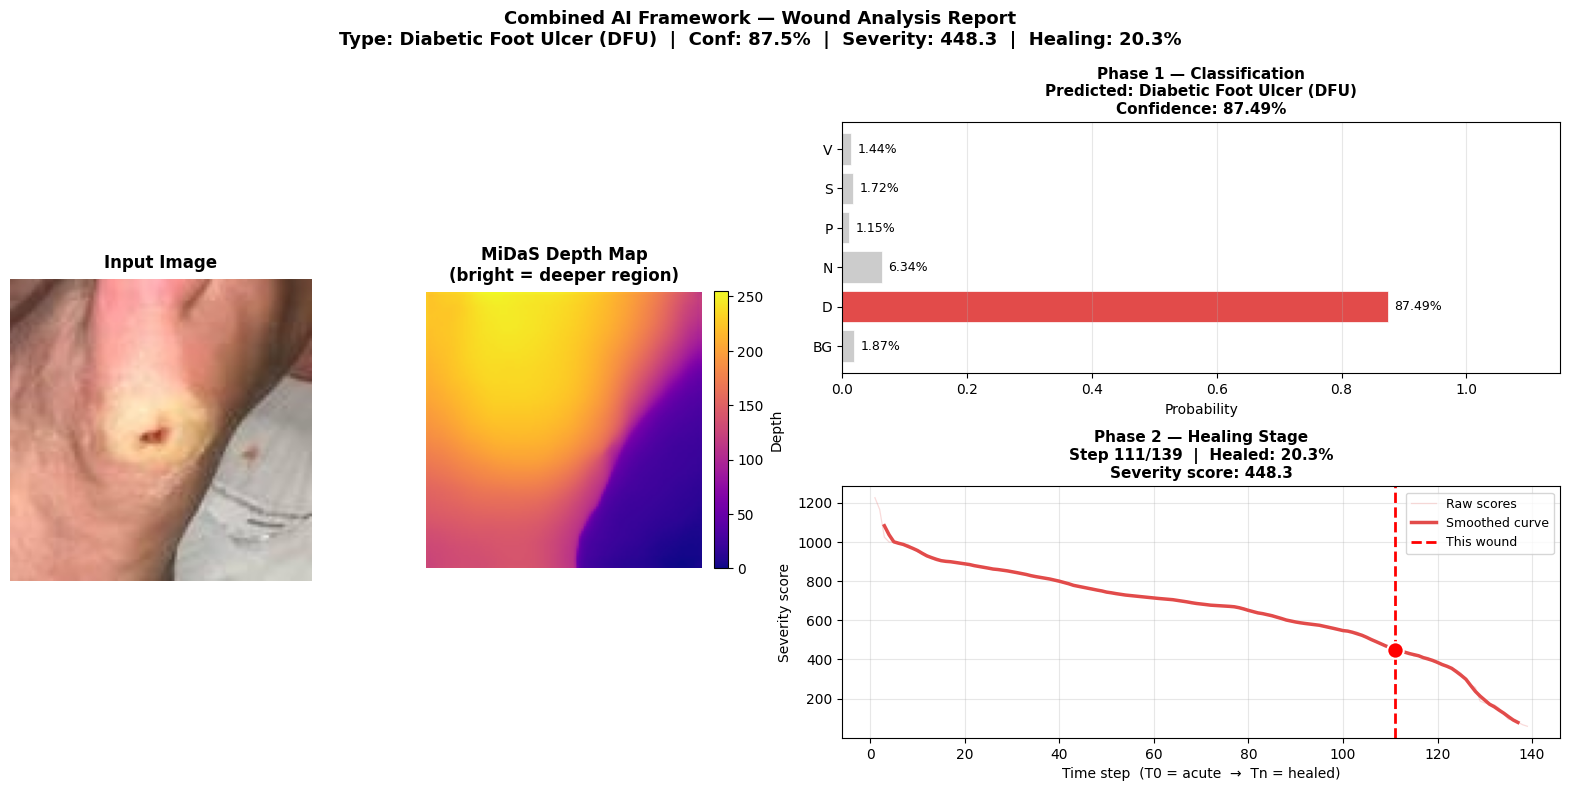


  [P] Pressure Ulcer (PU)
  Report saved → /kaggle/working/combined_output/report_P_Pressure.png


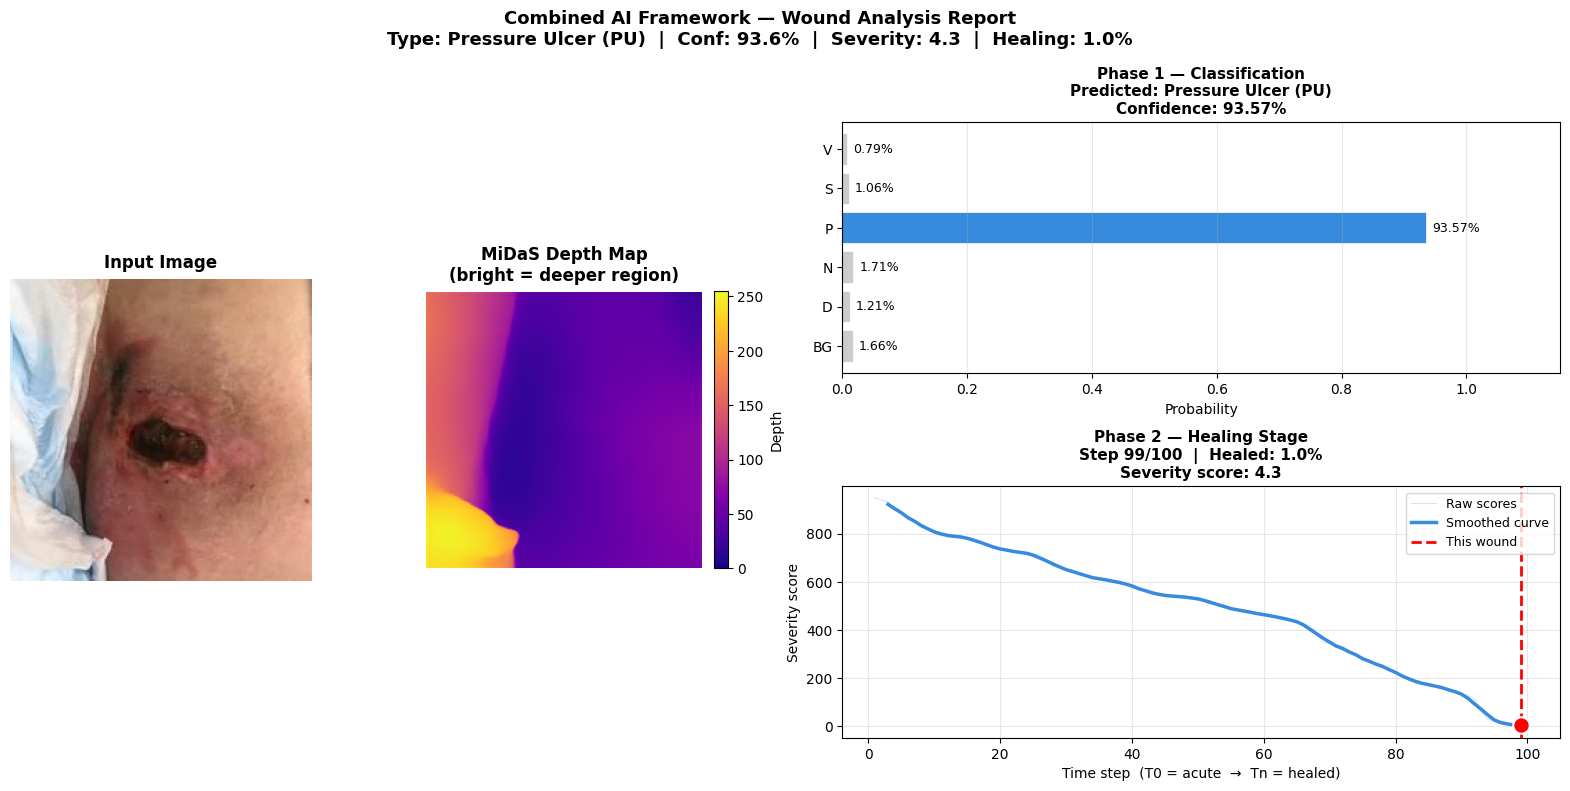


  [S] Surgical Wound (SW)
  Report saved → /kaggle/working/combined_output/report_S_Surgical.png


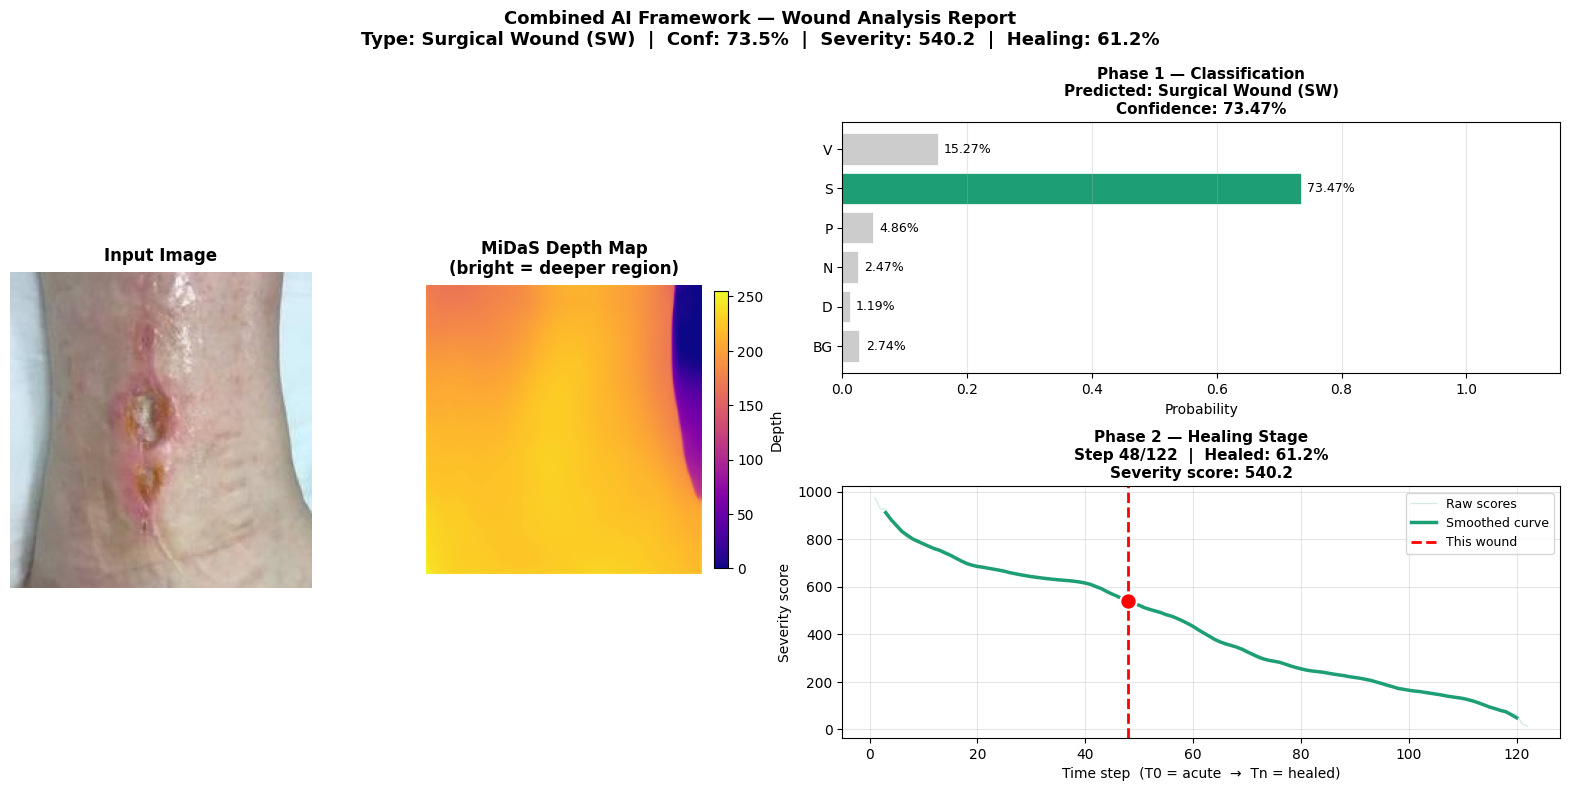


  [V] Venous Leg Ulcer (VLU)
  Report saved → /kaggle/working/combined_output/report_V_Venous.png


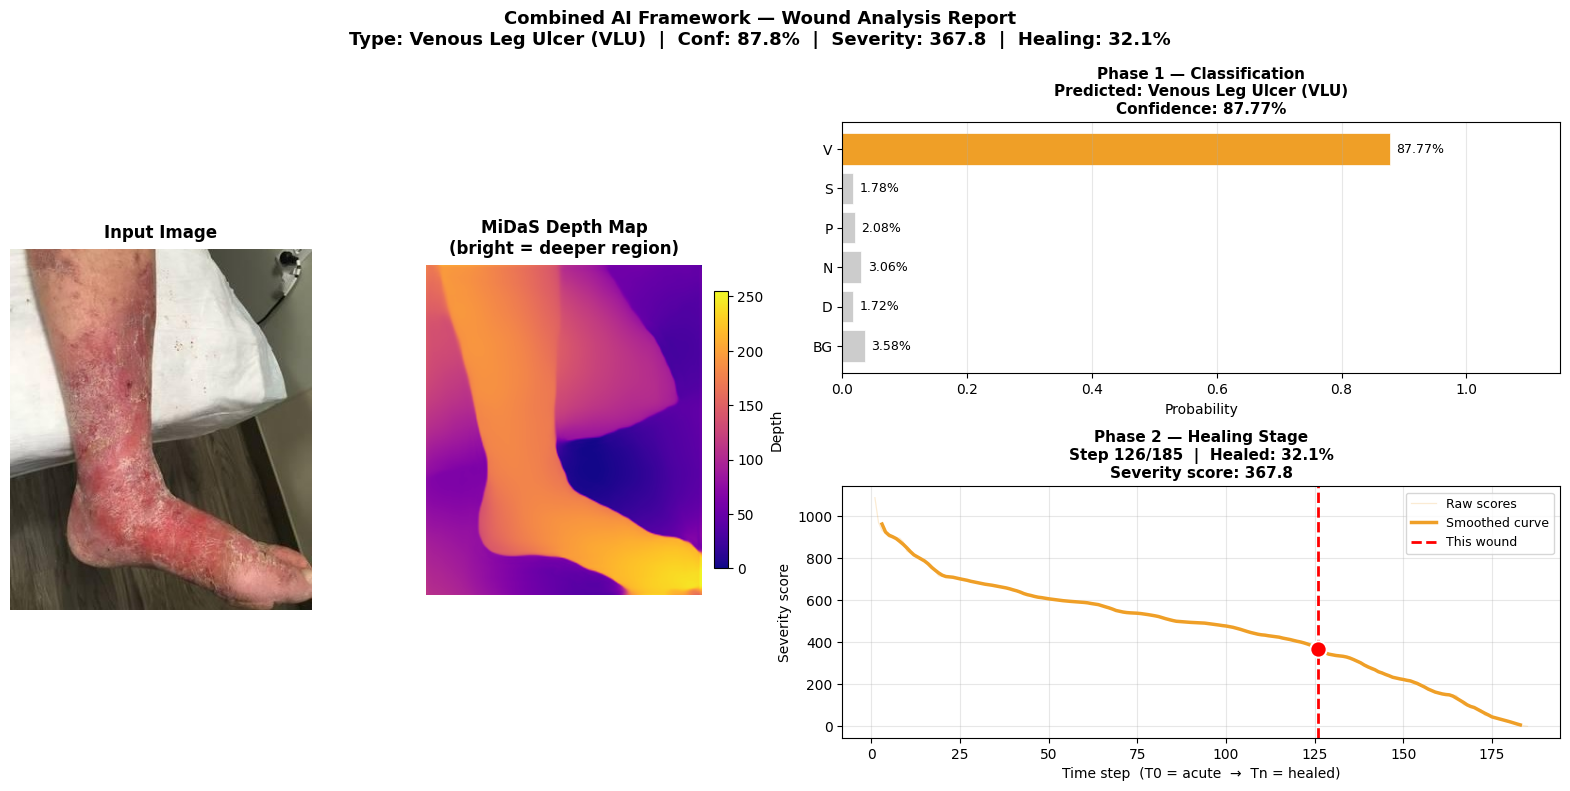

In [93]:

# ── Cell 15 : Generate one report card per wound class ───────
print("\nGenerating per-class report cards...")
seen = set()
for result in SAMPLE_RESULTS:
    cls = result["wound_type"]
    if cls in WOUND_CLASSES and cls not in seen:
        save_path = f"{COMBINED_OUT}/report_{cls}_{WOUND_DISPLAY[cls].split()[0]}.png"
        print(f"\n  [{cls}] {WOUND_DISPLAY[cls]}")
        visualize_result(result, save_path=save_path)
        seen.add(cls)
 


In [94]:

# ── Cell 16 : Aggregate summary table ────────────────────────
summary_rows = []
for r in SAMPLE_RESULTS:
    true_cls = Path(r["image_path"]).parent.name
    summary_rows.append({
        "filename"   : Path(r["image_path"]).name,
        "true_class" : true_cls,
        "predicted"  : r["wound_type"],
        "correct"    : true_cls == r["wound_type"],
        "confidence" : round(r["confidence"], 4),
        "severity"   : round(r["severity_score"], 2),
        "time_step"  : r["time_step"],
        "total_steps": r["total_steps"],
        "healing_pct": round(r["healing_pct"], 1) if r["healing_pct"] else None,
    })
 
summary_df = pd.DataFrame(summary_rows)
print("\n" + "=" * 75)
print("COMBINED FRAMEWORK — SAMPLE RESULTS")
print("=" * 75)
print(summary_df.to_string(index=False))
print(f"\nSample classification accuracy: {summary_df['correct'].mean():.2%}")
 
summary_df.to_csv(f"{COMBINED_OUT}/combined_results.csv", index=False)
print(f"\nResults saved → {COMBINED_OUT}/combined_results.csv")
 
 


COMBINED FRAMEWORK — SAMPLE RESULTS
 filename true_class predicted  correct  confidence  severity  time_step  total_steps  healing_pct
105_0.jpg          D         D     True      0.8749    448.29        111          139         20.3
106_0.jpg          D         D     True      0.8494    510.83        105          139         24.6
111_0.jpg          D         D     True      0.5557    250.72        128          139          8.0
100_0.jpg          P         P     True      0.9357      4.27         99          100          1.0
 12_0.jpg          P         P     True      0.7852    748.40         18          100         82.8
 15_0.jpg          P         P     True      0.9448    714.03         25          100         75.8
100_0.jpg          S         S     True      0.7347    540.17         48          122         61.2
104_0.jpg          S         S     True      0.9411     95.45        114          122          6.6
111_0.jpg          S         S     True      0.8799    389.56         63

In [95]:

# ── Cell 17 : Final system summary ───────────────────────────
print("\n" + "=" * 65)
print("FULL PIPELINE — SYSTEM SUMMARY")
print("=" * 65)
print(f"""
  PHASE 1 — Wound Classification (MobileNetV2)
  ─────────────────────────────────────────────
    Model       : MobileNetV2 (pretrained ImageNet)
    Classes     : {NUM_CLASSES} ({', '.join(CLASS_NAMES)})
    Image size  : {IMG_SIZE}×{IMG_SIZE}
    Test Acc    : {acc:.2%}
    F1-Score    : {f1:.4f}
 
  PHASE 2 — Depth-Based Severity Estimation (MiDaS)
  ──────────────────────────────────────────────────
    Model       : MiDaS_small (monocular depth)
    Classes     : 4 wound types (D, P, S, V)
    Output      : Pseudo-depth map + severity score
 
  INTEGRATION — Healing Progress Tracking
  ────────────────────────────────────────
    Input       : Single wound image
    Output      :
      → Wound type + confidence          [Phase 1]
      → Severity score (depth-based)     [Phase 2]
      → Healing stage (step T / Tn)      [Combined]
      → % healed estimate                [Combined]
 
  Example output:
    "This is a Diabetic Foot Ulcer (DFU) wound.
     Confidence: 94.3%
     Severity score: 142.7
     Healing stage: 12 of 47 steps (74.5% healed)"
""")
print("=" * 65)
print(f"All outputs → {COMBINED_OUT}/")



FULL PIPELINE — SYSTEM SUMMARY

  PHASE 1 — Wound Classification (MobileNetV2)
  ─────────────────────────────────────────────
    Model       : MobileNetV2 (pretrained ImageNet)
    Classes     : 6 (BG, D, N, P, S, V)
    Image size  : 224×224
    Test Acc    : 82.05%
    F1-Score    : 0.8206
 
  PHASE 2 — Depth-Based Severity Estimation (MiDaS)
  ──────────────────────────────────────────────────
    Model       : MiDaS_small (monocular depth)
    Classes     : 4 wound types (D, P, S, V)
    Output      : Pseudo-depth map + severity score
 
  INTEGRATION — Healing Progress Tracking
  ────────────────────────────────────────
    Input       : Single wound image
    Output      :
      → Wound type + confidence          [Phase 1]
      → Severity score (depth-based)     [Phase 2]
      → Healing stage (step T / Tn)      [Combined]
      → % healed estimate                [Combined]
 
  Example output:
    "This is a Diabetic Foot Ulcer (DFU) wound.
     Confidence: 94.3%
     Severity